# ResNet18 — 512×384 Resolution Experiment

## 1. Experiment Setup

### Objective
Investigate whether increasing image resolution from 384×288
to 512×384 improves distracted-driver classification.

### Configuration
- Architecture: ResNet18
- Initialization: ImageNet pretrained weights
- Fine-tuning: All layers
- Resolution: 512×384 (width × height)
- Training images: 15,732
- Validation images: 3,603
- Batch size: 32
- Optimizer: AdamW
- Backbone learning rate: 0.0001
- Classifier learning rate: 0.001
- Weight decay: 0.0001
- Maximum epochs: 15
- Minimum epochs: 7
- Early-stopping patience: 5
- Checkpoint selection: Best validation Macro-F1
- Seed: 42

### Evaluation
- Accuracy and Macro-F1
- Per-class precision, recall, and F1
- Confusion matrix
- Driver-specific accuracy
- Training and validation curves
- Training time and GPU memory

The final test dataset remains untouched.

In [1]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import torch
import torch.nn as nn
import torchvision

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import random
import time
import json

from pathlib import Path
from PIL import Image

from torchvision import models, transforms
from torchvision.transforms import InterpolationMode
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


# ============================================================
# 2. EXPERIMENT CONFIGURATION
# ============================================================

ROOT = Path("..")

SEED = 42

IMAGE_WIDTH = 512
IMAGE_HEIGHT = 384

BATCH_SIZE = 32

MAX_EPOCHS = 15
MIN_EPOCHS = 7
PATIENCE = 5

BACKBONE_LR = 0.0001
CLASSIFIER_LR = 0.001

WEIGHT_DECAY = 0.0001

# Set random seeds
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)


# ============================================================
# 3. LOAD DATASET SPLITS
# ============================================================

train_df = pd.read_csv(
    ROOT / "data/splits/driver_based/train.csv"
)

val_df = pd.read_csv(
    ROOT / "data/splits/driver_based/val.csv"
)

image_root = ROOT / "data/raw/imgs/train"

# Verify driver-independent splits
assert set(train_df["subject"]).isdisjoint(
    set(val_df["subject"])
)

assert len(train_df) == 15732
assert len(val_df) == 3603

print("\nTraining images:", len(train_df))
print("Validation images:", len(val_df))

print("Training drivers:", train_df["subject"].nunique())
print("Validation drivers:", val_df["subject"].nunique())


# ============================================================
# 4. IMAGENET NORMALIZATION
# ============================================================

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


# ============================================================
# 5. TRAINING AUGMENTATION
# ============================================================

train_transform = transforms.Compose([

    # Resize to 512×384
    transforms.Resize(
        (IMAGE_HEIGHT, IMAGE_WIDTH)
    ),

    # Small geometric transformations
    transforms.RandomAffine(
        degrees=5,
        translate=(0.04, 0.04),
        scale=(0.97, 1.03),
        interpolation=InterpolationMode.BILINEAR
    ),

    # Small lighting variations
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD
    )
])


# ============================================================
# 6. VALIDATION PREPROCESSING
# ============================================================

# No random augmentation for validation
val_transform = transforms.Compose([

    transforms.Resize(
        (IMAGE_HEIGHT, IMAGE_WIDTH)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD
    )
])


# ============================================================
# 7. DATASET CLASS
# ============================================================

class DriverDataset(Dataset):

    def __init__(self, dataframe, transform):
        self.data = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):

        row = self.data.iloc[idx]

        image_path = (
            image_root /
            row["classname"] /
            row["img"]
        )

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        image = self.transform(image)

        # c0 -> 0, c1 -> 1, ..., c9 -> 9
        label = int(row["classname"][1:])

        return image, label


# ============================================================
# 8. CREATE DATASETS
# ============================================================

train_dataset = DriverDataset(
    train_df,
    train_transform
)

val_dataset = DriverDataset(
    val_df,
    val_transform
)


# ============================================================
# 9. CREATE DATALOADERS
# ============================================================

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)


# ============================================================
# 10. VERIFY RESOLUTION
# ============================================================

train_images, train_labels = next(iter(train_loader))
val_images, val_labels = next(iter(val_loader))

print("\nTraining batch shape:", train_images.shape)
print("Validation batch shape:", val_images.shape)

assert train_images.shape[1:] == (3, 384, 512)
assert val_images.shape[1:] == (3, 384, 512)

print("\nResolution verified: 512×384 RGB")


# ============================================================
# 11. INITIALIZE FRESH PRETRAINED RESNET18
# ============================================================

weights = models.ResNet18_Weights.DEFAULT

model = models.resnet18(weights=weights)

# Replace ImageNet classifier with 10 classes
model.fc = nn.Linear(
    model.fc.in_features,
    10
)

model = model.to(device)

# Enable full fine-tuning
for parameter in model.parameters():
    parameter.requires_grad = True


# ============================================================
# 12. CONFIGURE OPTIMIZER
# ============================================================

backbone_params = [
    param
    for name, param in model.named_parameters()
    if not name.startswith("fc.")
]

classifier_params = list(model.fc.parameters())

optimizer = torch.optim.AdamW(
    [
        {
            "params": backbone_params,
            "lr": BACKBONE_LR
        },
        {
            "params": classifier_params,
            "lr": CLASSIFIER_LR
        }
    ],
    weight_decay=WEIGHT_DECAY
)

criterion = nn.CrossEntropyLoss()


# ============================================================
# 13. VERIFY MODEL
# ============================================================

total_parameters = sum(
    p.numel() for p in model.parameters()
)

trainable_parameters = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("\nModel: ResNet18")
print("Initialization: ImageNet pretrained")

print("Total parameters:", total_parameters)
print("Trainable parameters:", trainable_parameters)

model.eval()

with torch.no_grad():

    test_output = model(
        train_images[:2].to(device)
    )

print("\nModel output shape:", test_output.shape)

assert test_output.shape == (2, 10)


# ============================================================
# 14. CREATE RESULT DIRECTORIES
# ============================================================

exp_dir = (
    ROOT / "results/deep_learning/driver_based/"
    "resnet18/resolution_512x384"
)

model_dir = (
    ROOT / "models/deep_learning/driver_based/"
    "resnet18/resolution_512x384"
)

exp_dir.mkdir(parents=True, exist_ok=True)
model_dir.mkdir(parents=True, exist_ok=True)

best_model_path = model_dir / "best_model.pt"

history_path = exp_dir / "training_history.csv"
results_path = exp_dir / "results.json"
config_path = exp_dir / "configuration.json"


# ============================================================
# 15. SAVE EXPERIMENT CONFIGURATION
# ============================================================

config = {
    "model": "ResNet18",
    "pretrained": "ImageNet",
    "fine_tuning": "all_layers",

    "resolution": {
        "width": IMAGE_WIDTH,
        "height": IMAGE_HEIGHT
    },

    "training_images": len(train_dataset),
    "validation_images": len(val_dataset),

    "training_drivers": sorted(
        train_df["subject"].unique().tolist()
    ),
    "validation_drivers": sorted(
        val_df["subject"].unique().tolist()
    ),

    "optimizer": "AdamW",
    "backbone_lr": BACKBONE_LR,
    "classifier_lr": CLASSIFIER_LR,
    "weight_decay": WEIGHT_DECAY,

    "batch_size": BATCH_SIZE,

    "loss": "CrossEntropyLoss",

    "max_epochs": MAX_EPOCHS,
    "min_epochs": MIN_EPOCHS,
    "patience": PATIENCE,

    "augmentation": {
        "rotation_degrees": 5,
        "translation_fraction": 0.04,
        "scale": [0.97, 1.03],
        "brightness": 0.15,
        "contrast": 0.15,
        "horizontal_flip": False
    },

    "normalization": {
        "mean": IMAGENET_MEAN,
        "std": IMAGENET_STD
    },

    "checkpoint_selection": "validation_macro_f1",

    "seed": SEED,
    "device": str(device),
    "torch_version": torch.__version__,
    "torchvision_version": torchvision.__version__
}

with open(config_path, "w") as f:
    json.dump(config, f, indent=4)

print("\n" + "=" * 50)
print("RESNET18 — 512×384 EXPERIMENT READY")
print("=" * 50)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

print("Resolution:", f"{IMAGE_WIDTH}×{IMAGE_HEIGHT}")
print("Batch size:", BATCH_SIZE)

print("Backbone LR:", BACKBONE_LR)
print("Classifier LR:", CLASSIFIER_LR)

print("\nExperiment directory:", exp_dir)
print("Model directory:", model_dir)

Device: cuda
PyTorch: 2.14.1+cu132
Torchvision: 0.29.1+cu132

Training images: 15732
Validation images: 3603
Training drivers: 18
Validation drivers: 4

Training batch shape: torch.Size([32, 3, 384, 512])
Validation batch shape: torch.Size([32, 3, 384, 512])

Resolution verified: 512×384 RGB

Model: ResNet18
Initialization: ImageNet pretrained
Total parameters: 11181642
Trainable parameters: 11181642

Model output shape: torch.Size([2, 10])

RESNET18 — 512×384 EXPERIMENT READY
Training images: 15732
Validation images: 3603
Resolution: 512×384
Batch size: 32
Backbone LR: 0.0001
Classifier LR: 0.001

Experiment directory: ../results/deep_learning/driver_based/resnet18/resolution_512x384
Model directory: ../models/deep_learning/driver_based/resnet18/resolution_512x384


## 2. Full Fine-Tuning — 512×384

Train ImageNet-pretrained ResNet18 on 15,732 training images.

During every epoch:
1. Update all ResNet18 parameters.
2. Calculate training accuracy and loss.
3. Evaluate on 3,603 validation images.
4. Calculate validation accuracy and Macro-F1.
5. Save training metrics and execution times.
6. Save the checkpoint with the best validation Macro-F1.

Use early stopping to avoid unnecessary training.

Keep the final test set untouched.

In [2]:
# ============================================================
# 1. TRAINING PREPARATION
# ============================================================

history = []

best_f1 = -1.0
best_accuracy = 0.0
best_epoch = 0

epochs_without_improvement = 0

if device.type == "cuda":
    torch.cuda.reset_peak_memory_stats()
    torch.cuda.synchronize()

start_total = time.perf_counter()


# ============================================================
# 2. MAIN TRAINING LOOP
# ============================================================

for epoch in range(1, MAX_EPOCHS + 1):

    # --------------------------------------------------------
    # A. TRAINING
    # --------------------------------------------------------

    model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    if device.type == "cuda":
        torch.cuda.synchronize()

    start_train = time.perf_counter()

    for images, labels in train_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        # Reset gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update all ResNet18 weights
        optimizer.step()

        # Training predictions
        predictions = outputs.argmax(dim=1)

        batch_size = labels.size(0)

        train_loss_sum += (
            loss.item() * batch_size
        )

        train_correct += (
            predictions == labels
        ).sum().item()

        train_total += batch_size

    if device.type == "cuda":
        torch.cuda.synchronize()

    train_time = time.perf_counter() - start_train

    train_loss = train_loss_sum / train_total
    train_accuracy = train_correct / train_total


    # --------------------------------------------------------
    # B. VALIDATION
    # --------------------------------------------------------

    model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    all_true = []
    all_pred = []

    if device.type == "cuda":
        torch.cuda.synchronize()

    start_val = time.perf_counter()

    with torch.inference_mode():

        for images, labels in val_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            outputs = model(images)

            loss = criterion(outputs, labels)

            predictions = outputs.argmax(dim=1)

            batch_size = labels.size(0)

            val_loss_sum += (
                loss.item() * batch_size
            )

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += batch_size

            all_true.extend(
                labels.cpu().tolist()
            )

            all_pred.extend(
                predictions.cpu().tolist()
            )

    if device.type == "cuda":
        torch.cuda.synchronize()

    val_time = time.perf_counter() - start_val


    # --------------------------------------------------------
    # C. CALCULATE METRICS
    # --------------------------------------------------------

    val_loss = val_loss_sum / val_total
    val_accuracy = val_correct / val_total

    val_macro_f1 = f1_score(
        all_true,
        all_pred,
        labels=list(range(10)),
        average="macro",
        zero_division=0
    )

    epoch_time = train_time + val_time


    # --------------------------------------------------------
    # D. RECORD EPOCH RESULTS
    # --------------------------------------------------------

    history.append({
        "epoch": epoch,

        "train_loss": float(train_loss),
        "train_accuracy": float(train_accuracy),

        "val_loss": float(val_loss),
        "val_accuracy": float(val_accuracy),
        "val_macro_f1": float(val_macro_f1),

        "train_time_seconds": float(train_time),
        "val_time_seconds": float(val_time),
        "epoch_time_seconds": float(epoch_time)
    })

    # Save history after each epoch
    pd.DataFrame(history).to_csv(
        history_path,
        index=False
    )


    # --------------------------------------------------------
    # E. SAVE BEST CHECKPOINT
    # --------------------------------------------------------

    improved = (
        val_macro_f1 > best_f1 + 1e-4
    )

    if improved:

        best_f1 = float(val_macro_f1)
        best_accuracy = float(val_accuracy)
        best_epoch = epoch

        torch.save(
            model.state_dict(),
            best_model_path
        )


    # --------------------------------------------------------
    # F. PRINT RESULTS
    # --------------------------------------------------------

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Val F1: {val_macro_f1:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Time: {epoch_time:.1f}s",
        flush=True
    )


    # --------------------------------------------------------
    # G. EARLY STOPPING
    # --------------------------------------------------------

    # Start counting patience after the minimum epochs
    if epoch <= MIN_EPOCHS:

        epochs_without_improvement = 0

    else:

        if improved:
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= PATIENCE:

            print(
                f"\nEarly stopping at epoch {epoch}"
            )

            break


# ============================================================
# 3. CALCULATE TOTAL EXECUTION TIME
# ============================================================

if device.type == "cuda":
    torch.cuda.synchronize()

total_time = time.perf_counter() - start_total

peak_gpu_memory = (
    torch.cuda.max_memory_allocated() / (1024 ** 2)
    if device.type == "cuda"
    else None
)


# ============================================================
# 4. SAVE RESULTS
# ============================================================

history_df = pd.DataFrame(history)

best_record = history_df.loc[
    history_df["epoch"] == best_epoch
].iloc[0]

results = {
    "model": "ResNet18",

    "resolution": "512x384",

    "training_images": len(train_dataset),
    "validation_images": len(val_dataset),

    "epochs_completed": len(history),
    "best_epoch": int(best_epoch),

    "best_val_accuracy": float(best_accuracy),
    "best_val_macro_f1": float(best_f1),
    "best_val_loss": float(best_record["val_loss"]),

    "total_training_seconds": float(total_time),

    "peak_gpu_memory_mb": (
        float(peak_gpu_memory)
        if peak_gpu_memory is not None
        else None
    ),

    "best_checkpoint": str(best_model_path),
    "training_history": str(history_path)
}

with open(results_path, "w") as f:
    json.dump(results, f, indent=4)


# ============================================================
# 5. RESTORE THE BEST MODEL
# ============================================================

model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device,
        weights_only=True
    )
)

model.eval()


# ============================================================
# 6. DISPLAY SUMMARY
# ============================================================

print("\n" + "=" * 55)
print("RESNET18 — 512×384 TRAINING COMPLETED")
print("=" * 55)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

print("\nResolution: 512×384")

print("Epochs completed:", len(history))
print("Best epoch:", best_epoch)

print(
    f"\nValidation accuracy: "
    f"{best_accuracy:.4f} ({best_accuracy:.2%})"
)

print(
    f"Validation Macro-F1: "
    f"{best_f1:.4f} ({best_f1:.2%})"
)

print(
    f"\nTotal training time: "
    f"{total_time:.2f} seconds"
)

print(
    f"Peak GPU memory: "
    f"{peak_gpu_memory:.2f} MB"
    if peak_gpu_memory is not None
    else "GPU memory: N/A"
)

print("\nBest model:", best_model_path)
print("Results:", results_path)

print("\nTraining completed successfully!")

Epoch 01/15 | Train Acc: 0.9493 | Val Acc: 0.9031 | Val F1: 0.8911 | Val Loss: 0.3440 | Time: 142.9s
Epoch 02/15 | Train Acc: 0.9959 | Val Acc: 0.9151 | Val F1: 0.9118 | Val Loss: 0.3208 | Time: 142.3s
Epoch 03/15 | Train Acc: 0.9968 | Val Acc: 0.8937 | Val F1: 0.8711 | Val Loss: 0.6871 | Time: 142.1s
Epoch 04/15 | Train Acc: 0.9982 | Val Acc: 0.9087 | Val F1: 0.9003 | Val Loss: 0.2998 | Time: 139.6s
Epoch 05/15 | Train Acc: 0.9964 | Val Acc: 0.9051 | Val F1: 0.8903 | Val Loss: 0.3823 | Time: 141.5s
Epoch 06/15 | Train Acc: 0.9982 | Val Acc: 0.9228 | Val F1: 0.9140 | Val Loss: 0.3911 | Time: 141.7s
Epoch 07/15 | Train Acc: 0.9985 | Val Acc: 0.8898 | Val F1: 0.8854 | Val Loss: 0.3924 | Time: 141.2s
Epoch 08/15 | Train Acc: 0.9978 | Val Acc: 0.8770 | Val F1: 0.8624 | Val Loss: 0.5658 | Time: 142.2s
Epoch 09/15 | Train Acc: 0.9975 | Val Acc: 0.8707 | Val F1: 0.8534 | Val Loss: 0.4415 | Time: 142.9s
Epoch 10/15 | Train Acc: 0.9997 | Val Acc: 0.8837 | Val F1: 0.8692 | Val Loss: 0.5409 | Tim

## 3. Validation Inference and Error Analysis

Evaluate the best ResNet18 checkpoint at 512×384.

Calculate:
- Accuracy and Macro-F1
- Per-class classification report
- Driver-specific accuracy
- Normalized confusion matrix
- Safe-driving (c0) recall and c0 → c9 confusion rate

Save results for comparison with previous resolutions.

Loaded checkpoint: ../models/deep_learning/driver_based/resnet18/resolution_512x384/best_model.pt
Resolution: 512×384

RESNET18 — 512×384 VALIDATION RESULTS
Validation images: 3603
Accuracy: 0.9228 (92.28%)
Macro-F1: 0.9140 (91.40%)
Inference time: 12.72s

PER-CLASS CLASSIFICATION REPORT
              precision    recall  f1-score   support

          c0       0.80      0.95      0.87       372
          c1       1.00      0.98      0.99       377
          c2       0.93      0.98      0.95       367
          c3       0.99      0.98      0.99       393
          c4       0.96      0.97      0.96       378
          c5       0.99      0.99      0.99       372
          c6       0.82      1.00      0.90       372
          c7       0.93      0.98      0.96       342
          c8       0.96      0.59      0.73       298
          c9       0.90      0.71      0.79       332

    accuracy                           0.92      3603
   macro avg       0.93      0.91      0.91      3603
weighte

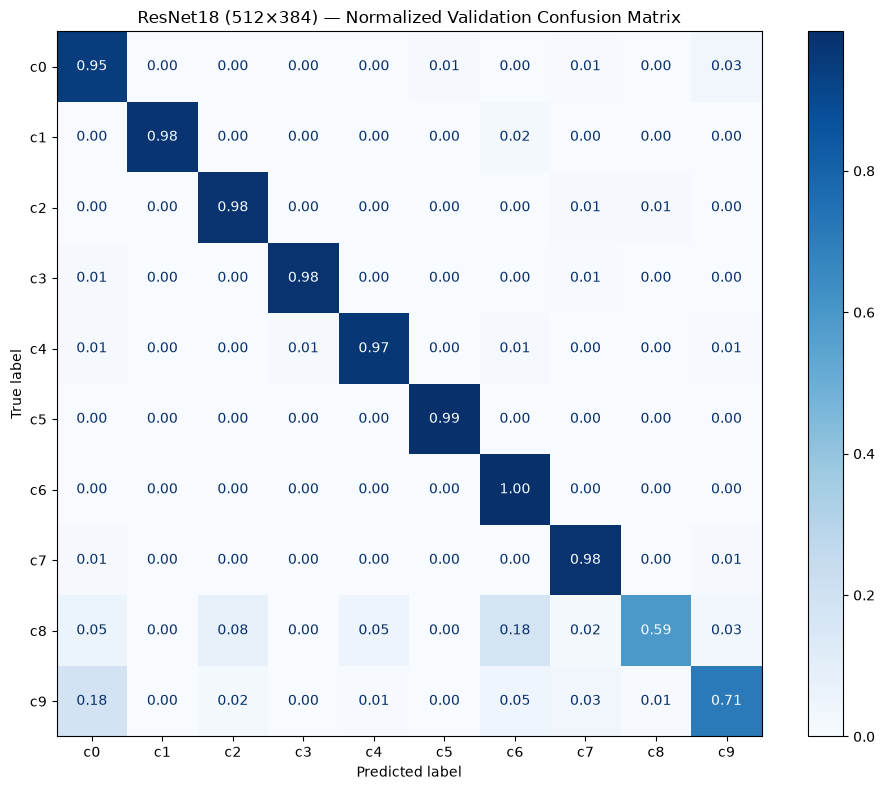


SAFE DRIVING (c0) ANALYSIS
Total c0 images: 372
Correct c0 predictions: 353
c0 Recall: 94.89%

c0 → c9 mistakes: 13
c0 → c9 error rate: 3.49%

Inference completed!
Results saved: ../results/deep_learning/driver_based/resnet18/resolution_512x384/error_analysis


In [3]:
import torch
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix
)

# ============================================================
# 1. LOAD THE BEST TRAINED MODEL
# ============================================================

model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device,
        weights_only=True
    )
)

model.eval()

print("Loaded checkpoint:", best_model_path)
print("Resolution: 512×384")


# ============================================================
# 2. RUN INFERENCE ON ALL VALIDATION IMAGES
# ============================================================

y_true = []
y_pred = []
confidences = []

if device.type == "cuda":
    torch.cuda.synchronize()

start = time.perf_counter()

with torch.inference_mode():

    for images, labels in val_loader:

        images = images.to(device)

        outputs = model(images)

        probabilities = torch.softmax(outputs, dim=1)

        confidence, predictions = probabilities.max(dim=1)

        y_true.extend(labels.tolist())
        y_pred.extend(predictions.cpu().tolist())
        confidences.extend(confidence.cpu().tolist())

if device.type == "cuda":
    torch.cuda.synchronize()

inference_time = time.perf_counter() - start


# ============================================================
# 3. CALCULATE VALIDATION METRICS
# ============================================================

accuracy = accuracy_score(y_true, y_pred)

macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    labels=list(range(10)),
    zero_division=0
)

print("\nRESNET18 — 512×384 VALIDATION RESULTS")
print("=" * 50)

print("Validation images:", len(y_true))
print(f"Accuracy: {accuracy:.4f} ({accuracy:.2%})")
print(f"Macro-F1: {macro_f1:.4f} ({macro_f1:.2%})")
print(f"Inference time: {inference_time:.2f}s")


# ============================================================
# 4. PER-CLASS CLASSIFICATION REPORT
# ============================================================

class_names = [f"c{i}" for i in range(10)]

print("\nPER-CLASS CLASSIFICATION REPORT")
print("=" * 50)

print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(10)),
        target_names=class_names,
        zero_division=0
    )
)


# ============================================================
# 5. SAVE INDIVIDUAL PREDICTIONS
# ============================================================

prediction_df = val_df.reset_index(drop=True).copy()

assert len(prediction_df) == len(y_true)

assert (
    prediction_df["classname"]
    .str[1:]
    .astype(int)
    .tolist() == y_true
)

prediction_df["predicted"] = [f"c{x}" for x in y_pred]
prediction_df["confidence"] = confidences

prediction_df["correct"] = (
    prediction_df["classname"] == prediction_df["predicted"]
)


# ============================================================
# 6. ACCURACY BY DRIVER
# ============================================================

driver_results = (
    prediction_df
    .groupby("subject")
    .agg(
        images=("correct", "size"),
        accuracy=("correct", "mean")
    )
    .sort_values("accuracy")
)

print("\nACCURACY BY DRIVER")
print("=" * 50)

print(driver_results.to_string())


# ============================================================
# 7. CREATE ERROR ANALYSIS DIRECTORY
# ============================================================

analysis_dir = exp_dir / "error_analysis"
analysis_dir.mkdir(parents=True, exist_ok=True)

prediction_df.to_csv(
    analysis_dir / "validation_predictions.csv",
    index=False
)

driver_results.to_csv(
    analysis_dir / "driver_accuracy.csv"
)


# ============================================================
# 8. NORMALIZED CONFUSION MATRIX
# ============================================================

fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=list(range(10)),
    display_labels=class_names,
    normalize="true",
    cmap="Blues",
    values_format=".2f",
    ax=ax
)

ax.set_title(
    "ResNet18 (512×384) — Normalized Validation Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    analysis_dir / "confusion_matrix_normalized.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 9. ANALYZE SAFE DRIVING (c0)
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(10))
)

c0_total = cm[0].sum()
c0_correct = cm[0, 0]
c0_to_c9 = cm[0, 9]

print("\nSAFE DRIVING (c0) ANALYSIS")
print("=" * 50)

print("Total c0 images:", c0_total)
print("Correct c0 predictions:", c0_correct)
print(f"c0 Recall: {c0_correct / c0_total:.2%}")

print("\nc0 → c9 mistakes:", c0_to_c9)
print(f"c0 → c9 error rate: {c0_to_c9 / c0_total:.2%}")

print("\nInference completed!")
print("Results saved:", analysis_dir)